## HelixRT: Model Evaluation and Comparative Analysis

### Overview

This notebook evaluates the predictive performance and reverse-complement consistency of deep learning models for human enhancer classification.

The primary objective is to investigate whether enforcing biological symmetry within a neural network can eliminate strand-dependent prediction inconsistencies while preserving classification performance.

We compare six model configurations:

- GC-content Logistic Regression
- Standard CNN
- Reverse-complement Augmented CNN
- Standard CNN with Test-Time Augmentation (TTA)
- Augmented CNN with Test-Time Augmentation (TTA)
- HelixRT: Reverse-complement Invariant CNN

All neural network architectures were trained using three random seeds (42, 123, and 456), with a maximum training budget of 100 epochs and early stopping based on validation AUROC.

The official test set of 6,948 genomic sequences was reserved for final evaluation.

### Research Questions

1. Can convolutional neural networks learn predictive information beyond GC content alone?
2. To what extent do conventional CNNs exhibit reverse-complement prediction inconsistency?
3. Does reverse-complement data augmentation reduce prediction inconsistency?
4. Can architectural invariance eliminate strand-dependent prediction differences while preserving predictive performance?
5. How does architectural invariance compare with test-time prediction averaging?



### 1. Imports and Experimental Configuration

Initialize the required libraries, project directories, model identifiers, and visualization settings.


In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

PROJECT_ROOT = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())

RESULTS_DIR = PROJECT_ROOT / "results"

FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

MODEL_NAMES = {
    "gc_baseline": "GC Baseline",
    "standard": "Standard CNN",
    "augmented": "Augmented CNN",
    "standard_tta": "Standard + TTA",
    "augmented_tta": "Augmented + TTA",
    "invariant": "HelixRT"
}

COLORS = {
    "gc_baseline": "#94A3B8",
    "standard": "#64748B",
    "augmented": "#2563EB",
    "standard_tta": "#D97706",
    "augmented_tta": "#8B5CF6",
    "invariant": "#059669"
}

MODEL_ORDER = [
    "gc_baseline",
    "standard",
    "augmented",
    "standard_tta",
    "augmented_tta",
    "invariant"
]

SEEDS = [42, 123, 456]

print("Project root:", PROJECT_ROOT)
print("Figures directory:", FIGURES_DIR)

Project root: d:\Github\Personal_Projects\HelixRT
Figures directory: d:\Github\Personal_Projects\HelixRT\results\figures


### 2. Loading Experimental Results

Load the training histories, held-out test metrics, aggregated model comparisons, and individual sequence
predictions generated by the training and evaluation pipelines.

The nine training histories correspond to three neural network configurations trained across three independent random seeds.

The test evaluation includes 16 runs across six model configurations, producing 111,168 individual prediction records.

Combining these results into structured dataframes enables comparative analysis across architectures, random seeds, training epochs, and individual sequences.

In [5]:
test_metrics = pd.read_csv(RESULTS_DIR / "test_metrics.csv")
model_comparison = pd.read_csv(RESULTS_DIR / "model_comparison.csv")
test_predictions = pd.read_csv(RESULTS_DIR / "test_predictions.csv")

histories = []

for model in ["standard", "augmented", "invariant"]:
    for seed in SEEDS:
        path = (RESULTS_DIR / f"{model}_seed{seed}_epochs100_history.csv")

        history = pd.read_csv(path)
        history["model"] = model
        history["seed"] = seed
        histories.append(history)

training_history = pd.concat(histories, ignore_index=True)

print("Test metric rows:", len(test_metrics))
print("Model configurations:", len(model_comparison))
print("Test prediction rows:", len(test_predictions))
print("Training history rows:", len(training_history))

display(model_comparison)

Test metric rows: 16
Model configurations: 6
Test prediction rows: 111168
Training history rows: 880


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,auroc_mean,...,log_loss_std,rc_mean_error_mean,rc_mean_error_std,rc_max_error_mean,rc_max_error_std,rc_flip_rate_mean,rc_flip_rate_std,rc_flip_count_mean,rc_flip_count_std,n_runs
0,invariant,0.736807,0.002958,0.741441,0.017388,0.728843,0.033583,0.734503,0.008788,0.814385,...,0.001894,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3
1,augmented_tta,0.734744,0.001603,0.750110,0.010678,0.704567,0.019151,0.726420,0.005577,0.813487,...,0.000750,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3
2,standard_tta,0.729371,0.001257,0.720404,0.020270,0.752639,0.046622,0.735182,0.011046,0.810583,...,0.005402,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3
3,augmented,0.730762,0.003289,0.746692,0.006759,0.698810,0.021803,0.721764,0.008708,0.810255,...,0.002666,0.053970,0.003246,0.387139,0.053789,0.080983,0.004046,562.666667,28.112868,3
4,standard,0.729035,0.001198,0.720075,0.020921,0.752543,0.048609,0.734886,0.011524,0.806547,...,0.004817,0.072175,0.004270,0.508124,0.071564,0.106218,0.004535,738.000000,31.511903,3
5,gc_baseline,0.669113,NaN,0.679609,NaN,0.639896,NaN,0.659155,NaN,0.733919,...,NaN,0.000000,NaN,0.000000,NaN,0.000000,NaN,0.000000,NaN,1


### 3. Experimental Integrity and Data Validation

Before analyzing the results, verify that the evaluation pipeline has produced complete and internally consistent experimental records.

The following checks ensure that:

- All 16 evaluation runs are present.
- All six model configurations are represented.
- Every evaluation run contains 6,948 test predictions.
- AUROC is defined for every evaluation run.
- No duplicate prediction records exist.
- Ground-truth labels are consistent across experiments.
- Predicted probabilities fall within the valid range of 0 to 1.

These checks help prevent incomplete evaluations, misaligned predictions, or invalid numerical results
from influencing subsequent analysis.

In [6]:
assert len(test_metrics) == 16

assert len(model_comparison) == 6

assert len(test_predictions) == 111168

assert test_metrics["auroc"].notna().all()

samples_per_run = test_predictions.groupby(["model", "seed"]).size()

assert (samples_per_run == 6948).all()

assert not test_predictions.duplicated(subset=["model", "seed", "sequence_id"]).any()

label_consistency = test_predictions.groupby("sequence_id")["label"].nunique()

assert (label_consistency == 1).all()

assert test_predictions["probability"].between(0, 1).all()

assert test_predictions["rc_probability"].between(0, 1).all()

print("All experimental integrity checks passed.")

All experimental integrity checks passed.


### 4. Training Dynamics and Generalization

#### 4.1 Training and Validation Loss

Binary cross-entropy loss measures the discrepancy between predicted probabilities and ground-truth labels.

Training loss reflects how effectively a model is learning from its training samples, while validation
loss measures its performance on previously unseen validation sequences.

Comparing these curves helps identify convergence, underfitting, and potential overfitting.

Individual training runs are represented by faint lines, while the thicker lines represent the mean loss across available random seeds at each epoch.

Because early stopping results in different training durations, the number of runs contributing to the mean may decrease at later epochs.

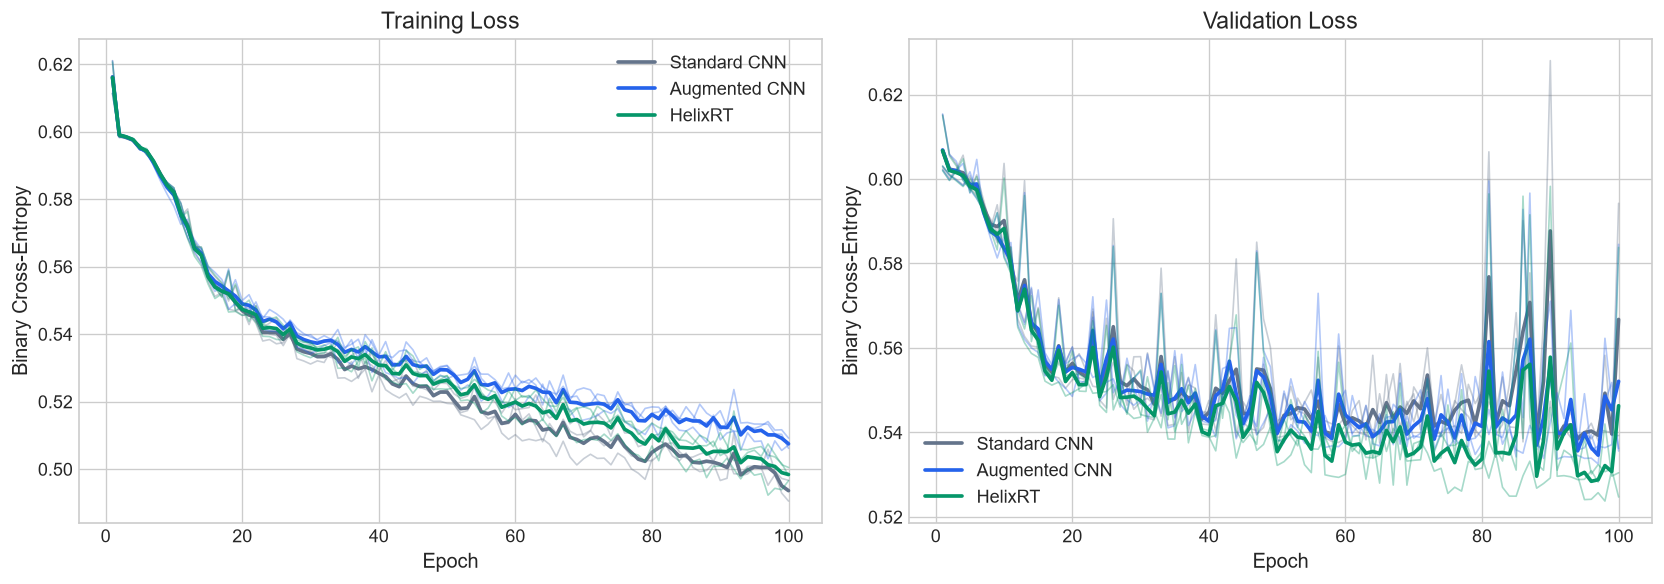

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

for model in ["standard", "augmented", "invariant"]:
    subset = training_history[training_history["model"] == model]

    for ax, metric in zip(axes, ["train_loss", "val_loss"]):
        for seed in SEEDS:
            run = subset[subset["seed"] == seed]

            ax.plot(run["epoch"], run[metric], color=COLORS[model], alpha=0.35, linewidth=1)
        
        mean_values = subset.groupby("epoch")[metric].mean()

        ax.plot(mean_values.index, mean_values.values, label=MODEL_NAMES[model], color=COLORS[model], linewidth=2.2)

axes[0].set_title("Training Loss")
axes[1].set_title("Validation Loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy")
    ax.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "training_loss_comparison.png",
    bbox_inches="tight"
)
plt.show()

#### 4.2 Validation AUROC During Training

The Area Under the Receiver Operating Characteristic Curve (AUROC) measures a classifier's ability to
distinguish positive examples from negative examples across classification thresholds.

In this experiment, AUROC represents the probability that a randomly selected enhancer receives a higher
prediction score than a randomly selected non-enhancer, with ties counted as half-correct.

The GC-content logistic regression baseline is included as a reference to determine whether the neural networks learn predictive sequence information beyond simple nucleotide composition.

Validation AUROC is also the checkpoint-selection criterion used during training.

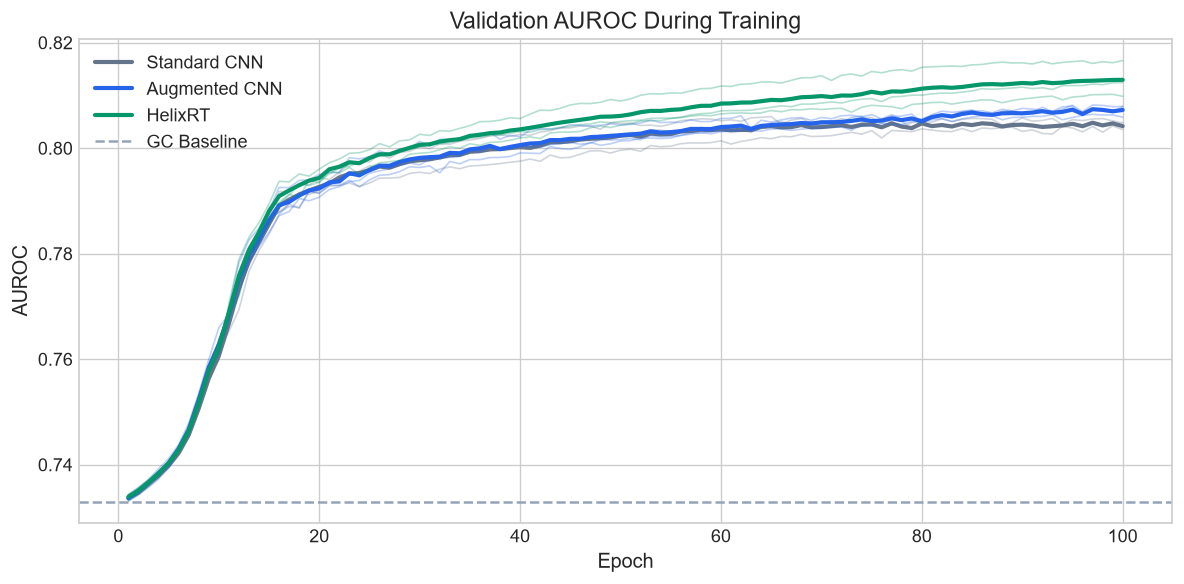

In [8]:
fig, ax = plt.subplots(figsize=(10,5))

gc_baseline = pd.read_csv(RESULTS_DIR / "gc_baseline.csv")

gc_auroc = gc_baseline["auroc"].iloc[0]

for model in ["standard", "augmented", "invariant"]:
    subset = training_history[training_history["model"] == model]

    for seed in SEEDS:
        run = subset[subset["seed"] == seed]

        ax.plot(run["epoch"], run["val_auroc"], color=COLORS[model], alpha=0.3, linewidth=1)
    
    mean_auroc = subset.groupby("epoch")["val_auroc"].mean()

    ax.plot(mean_auroc.index, mean_auroc.values, label=MODEL_NAMES[model], color=COLORS[model], linewidth=2.5)

ax.axhline(gc_auroc, linestyle="--", color=COLORS["gc_baseline"], label="GC Baseline")

ax.set_title("Validation AUROC During Training")
ax.set_xlabel("Epoch")
ax.set_ylabel("AUROC")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "validation_auroc_curves.png",
    bbox_inches="tight"
)

plt.show()

### 5. Reverse-Complement Consistency During Training

DNA sequences can be represented using either strand of the same double-stranded DNA segment.

For strand-independent enhancer classification, a model should produce equivalent predictions for a DNA
sequence and its reverse complement.

#### Mean Reverse-Complement Error

For a sequence $x$ and its reverse complement $RC(x)$, the prediction disagreement is defined as:

$$
e_{RC}(x) = |f(x) - f(RC(x))|
$$

The mean reverse-complement error across a dataset containing $N$ sequences is:

$$
E_{RC} =
\frac{1}{N}
\sum_{i=1}^{N}
|f(x_i) - f(RC(x_i))|
$$

#### Classification Flip Rate

The classification flip rate measures the proportion of sequences whose predicted class changes when the
input is reverse-complemented.

$$
\text{Flip Rate} =
\frac{1}{N}
\sum_{i=1}^{N}
\mathbb{1}
[\hat{y}(x_i) \neq \hat{y}(RC(x_i))]
$$

Both metrics are evaluated throughout training to investigate whether improved predictive performance
is accompanied by increased biological inconsistency.

The HelixRT architecture enforces reverse-complement invariance through shared feature extraction and
symmetric feature aggregation.

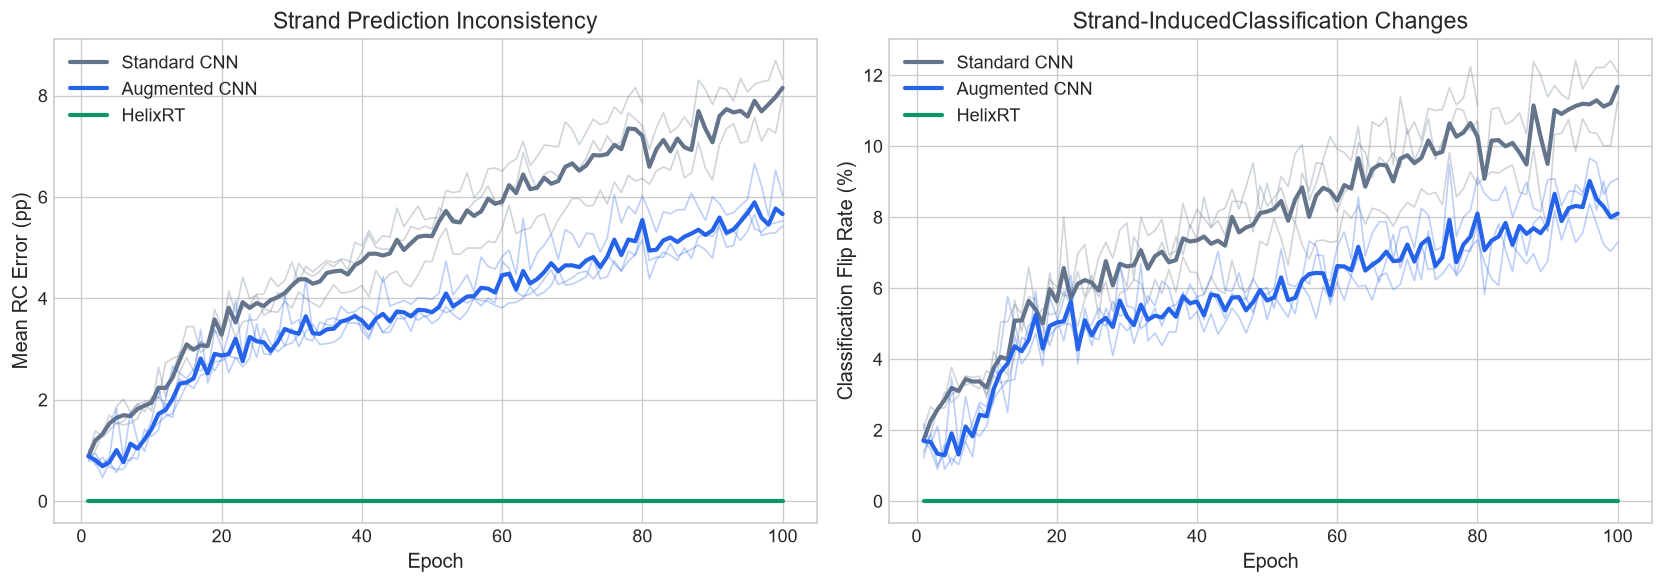

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

metrics = [
    ("rc_mean_error", "Mean RC Error (pp)"),
    ("rc_flip_rate", "Classification Flip Rate (%)")
]

for model in ["standard", "augmented", "invariant"]:
    subset = training_history[training_history["model"] == model]
    
    for ax, (metric, ylabel) in zip(axes, metrics):
        for seed in SEEDS:
            run = subset[subset["seed"] == seed]

            ax.plot(run["epoch"], run[metric]*100, color=COLORS[model], alpha=0.3, linewidth=1)
        
        mean_metric = subset.groupby("epoch")[metric].mean()

        ax.plot(mean_metric.index, mean_metric.values*100, label=MODEL_NAMES[model], color=COLORS[model], linewidth=2.5)

        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)

axes[0].set_title("Strand Prediction Inconsistency")
axes[1].set_title("Strand-InducedClassification Changes")

for ax in axes:

    ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "rc_consistency_training.png",
    bbox_inches="tight"
)

plt.show()

#### Observations

The standard CNN exhibits increasing reverse-complement prediction disagreement as training progresses.

Reverse-complement augmentation reduces this inconsistency, but does not guarantee identical
predictions across strand representations.

HelixRT maintains zero observed reverse-complement error and classification flip rate throughout the
recorded validation experiments.

This behavior follows from its architectural design rather than a learned approximation of strand symmetry.

These results demonstrate that classification performance and biological consistency are distinct properties that should be evaluated independently.

### 6. Held-Out Test Performance

#### 6.1 Aggregate Classification Performance

Evaluate the frozen model checkpoints on the official test dataset containing 6,948 genomic sequences.

The selected checkpoints correspond to the highest validation AUROC achieved during each training run.

Neural network results are aggregated across three random seeds and reported using the mean and sample
standard deviation.

The GC-content baseline was evaluated once, so its sample standard deviation is undefined.

Two primary classification metrics are examined:

- **AUROC:** Measures predictive discrimination across classification thresholds.
- **Accuracy:** Measures the proportion of correctly classified sequences at a probability threshold of 0.5.

Test-time augmentation is included as an additional comparison that enforces reverse-complement invariance
through prediction averaging without retraining.

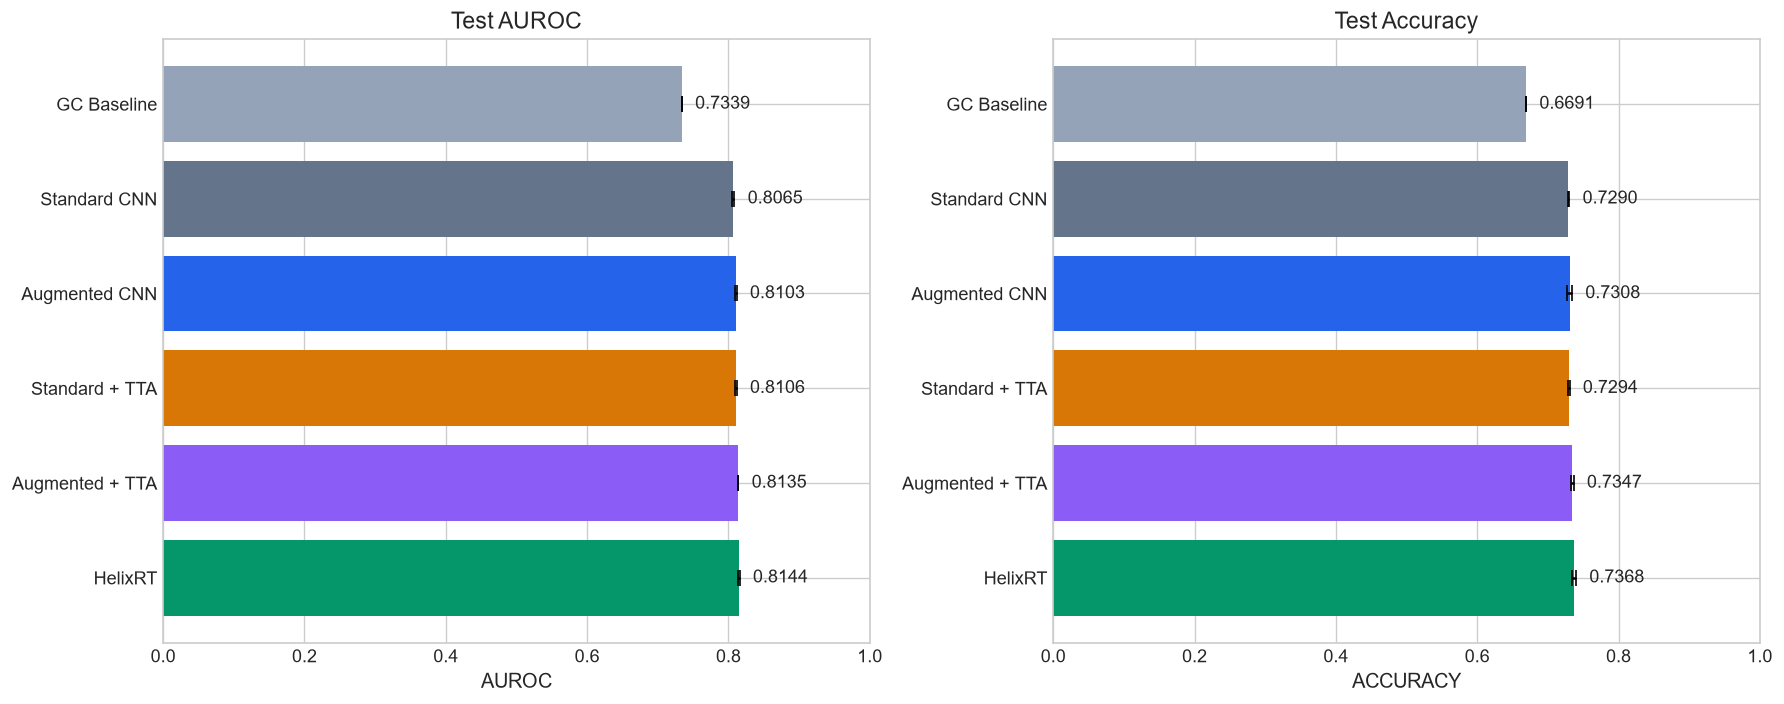

In [11]:
comparison = model_comparison.set_index("model").loc[MODEL_ORDER].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

names = [MODEL_NAMES[model] for model in comparison["model"]]

colors = [COLORS[model] for model in comparison["model"]]

metrics = [
    ("auroc", "Test AUROC"),
    ("accuracy", "Test Accuracy"),
]

for ax, (metric, title) in zip(axes, metrics):
    means = comparison[f"{metric}_mean"]
    errors = comparison[f"{metric}_std"].fillna(0)

    bars = ax.barh(names, means, xerr=errors, color=colors, capsize=5)
    ax.bar_label(bars, fmt="%.4f", padding=8)

    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel(metric.upper())
    ax.invert_yaxis()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_performance_comparison.png", bbox_inches="tight")
plt.show()

### Observations

HelixRT achieves the highest observed mean test AUROC of 0.8144 across three random seeds, compared with
0.8065 for the standard CNN and 0.8103 for the augmented CNN.

All CNN configurations substantially outperform the GC-content baseline, suggesting that they capture
additional predictive information beyond simple GC composition.

The augmented CNN with test-time augmentation achieves an AUROC of 0.8135, which is very close to HelixRT.

Although HelixRT achieves the highest observed mean AUROC, the small difference relative to augmented TTA
does not establish statistical superiority.

Overall, the results indicate that architectural invariance can be enforced without a substantial
reduction in predictive performance.

#### 6.2 Receiver Operating Characteristic Curves

Receiver Operating Characteristic (ROC) curves visualize the relationship between the true positive rate and false positive rate across classification thresholds.

A stronger classifier generally produces a curve closer to the upper-left corner, indicating a higher detection rate at a lower false positive rate.

The diagonal reference line represents random classification performance.

For visualization, seed 42 is used consistently across all neural network configurations. This avoids selecting a different best-performing seed for each architecture.

The aggregated results across all three seeds remain the primary basis for model comparison.

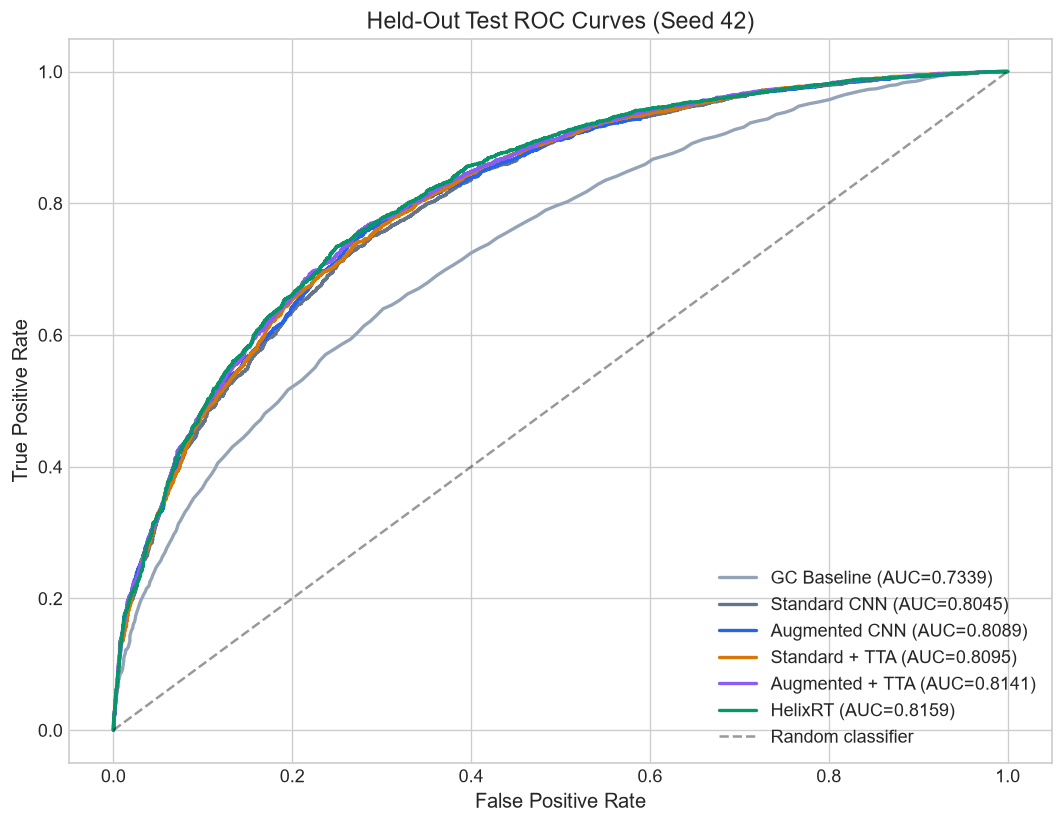

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))

for model in MODEL_ORDER:

    subset = test_predictions[(test_predictions["model"] == model) & (test_predictions["seed"] == 42) ]

    labels = subset["label"]

    probabilities = subset["probability"]

    fpr, tpr, _ = roc_curve(labels, probabilities)

    auc = roc_auc_score(labels, probabilities)

    ax.plot(
        fpr,
        tpr,
        color=COLORS[model],
        linewidth=2,
        label=(
            f"{MODEL_NAMES[model]} "
            f"(AUC={auc:.4f})"
        )
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    alpha=0.4,
    label="Random classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.set_title("Held-Out Test ROC Curves (Seed 42)")

ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(FIGURES_DIR / "test_roc_curves.png", bbox_inches="tight")

plt.show()

### 7. Distribution of Reverse-Complement Prediction Errors

Mean reverse-complement error summarizes the overall level of strand inconsistency, but does not reveal how individual prediction disagreements are distributed.

Analyzing the distribution of absolute probability differences helps distinguish frequent small errors
from less common but potentially severe inconsistencies.

The following histogram compares reverse-complement prediction errors for the standard, augmented, and
architecturally invariant CNNs across all three training seeds.

For a perfectly invariant model, all observations should be concentrated at zero, subject to numerical
precision.

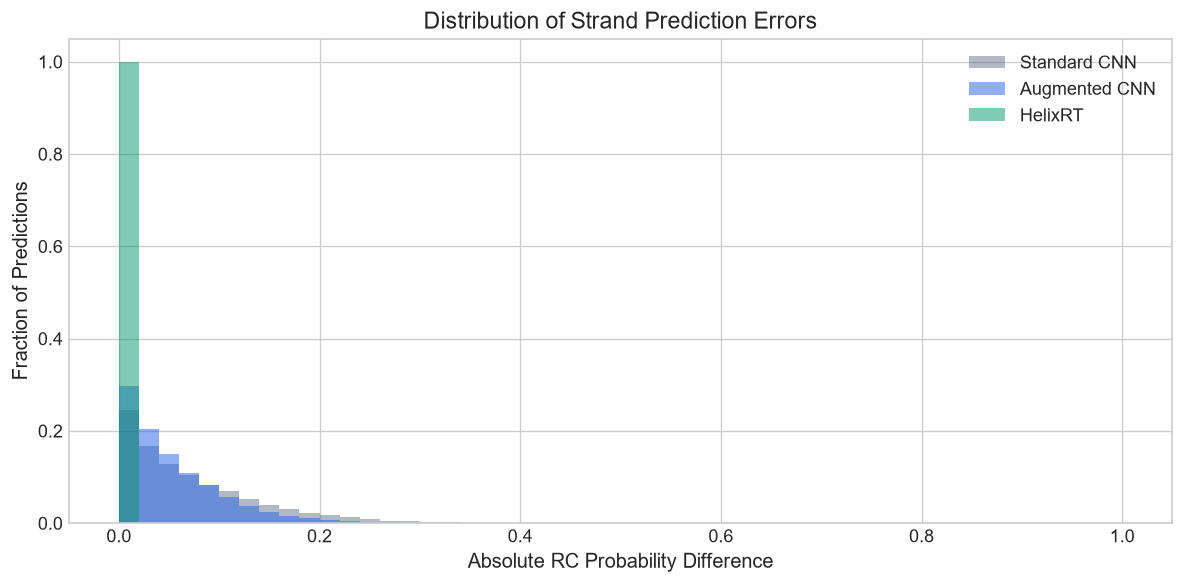

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

bins = np.linspace(0, 1, 51)

for model in ["standard", "augmented", "invariant"]:

    subset = test_predictions[test_predictions["model"] == model]

    ax.hist(
        subset["rc_error"],
        bins=bins,
        weights=np.ones(len(subset)) / len(subset),
        alpha=0.5,
        label=MODEL_NAMES[model],
        color=COLORS[model]
    )

ax.set_xlabel("Absolute RC Probability Difference")
ax.set_ylabel("Fraction of Predictions")
ax.set_title("Distribution of Strand Prediction Errors")

ax.legend()

plt.tight_layout()

plt.savefig(FIGURES_DIR / "rc_error_distribution.png", bbox_inches="tight")

plt.show()

#### Observations

The standard CNN exhibits nonzero prediction disagreement across equivalent DNA representations.

Reverse-complement augmentation reduces the average magnitude of these disagreements, although inconsistent predictions remain.

HelixRT's observed error distribution is concentrated at zero, consistent with its mathematical invariance
property.

Zero reverse-complement error does not imply perfect classification. It establishes that the model's
predictions are independent of strand representation for this classification task.

### 8. Predictive Performance vs Biological Consistency

A useful genomic classifier should demonstrate both strong predictive discrimination and consistency with
known biological constraints.

To investigate the relationship between these properties, we compare test AUROC against mean reverse-complement prediction error.

The desirable region of this comparison is characterized by high AUROC and low reverse-complement error.

This experiment distinguishes between three approaches to handling DNA strand symmetry:

1. Conventional learning without explicit symmetry constraints.
2. Approximate invariance through data augmentation.
3. Mathematical invariance through architectural design or test-time prediction averaging.

Individual markers represent independent training runs, while larger markers represent the mean performance of each model configuration.

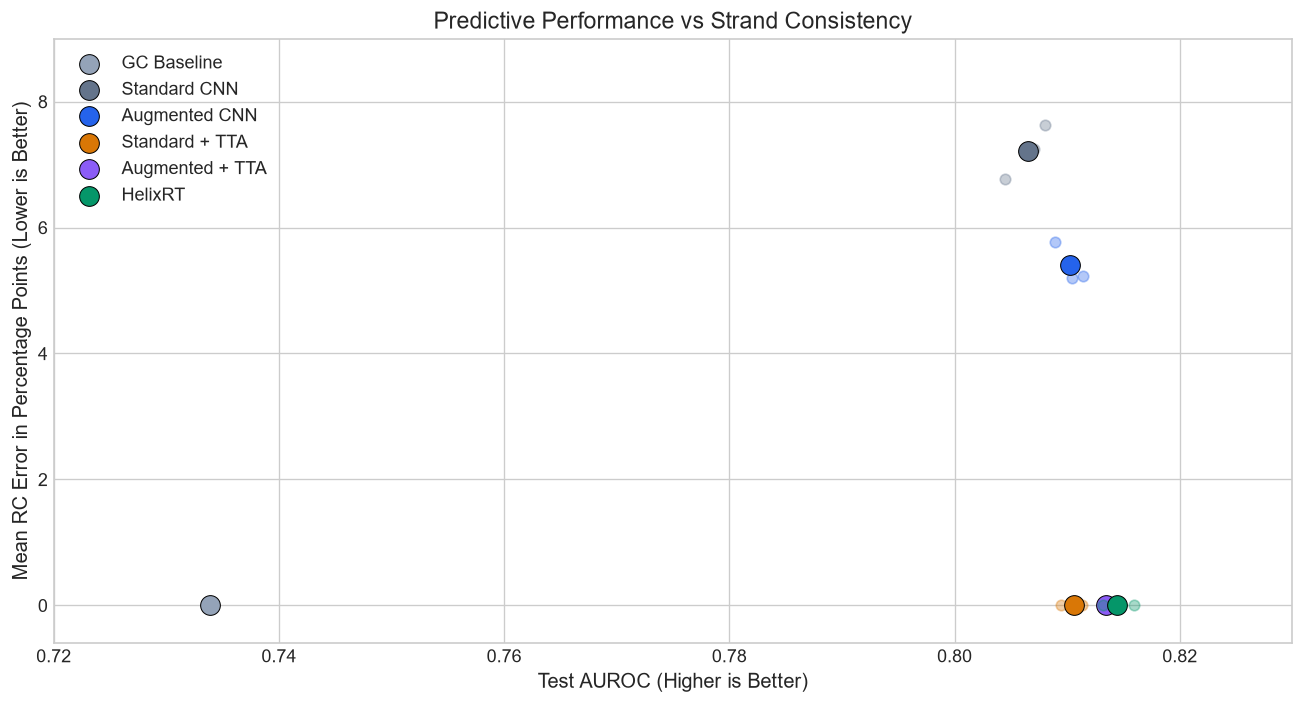

In [14]:
fig, ax = plt.subplots(figsize=(11, 6))

for model in MODEL_ORDER:

    subset = test_metrics[test_metrics["model"] == model]

    x = subset["auroc"].mean()

    y = subset["rc_mean_error"].mean() * 100

    ax.scatter(
        subset["auroc"],
        subset["rc_mean_error"] * 100,
        color=COLORS[model],
        s=40,
        alpha=0.35
    )

    ax.scatter(
        x,
        y,
        color=COLORS[model],
        s=140,
        edgecolor="black",
        linewidth=0.6,
        label=MODEL_NAMES[model]
    )

ax.set_xlabel("Test AUROC (Higher is Better)")

ax.set_ylabel(
    "Mean RC Error in Percentage Points "
    "(Lower is Better)"
)

ax.set_title("Predictive Performance vs Strand Consistency")

ax.set_xlim(0.72, 0.83)
ax.set_ylim(-0.6, 9)

ax.legend(loc="upper left")

plt.tight_layout()

plt.savefig(FIGURES_DIR / "accuracy_consistency_tradeoff.png", bbox_inches="tight")

plt.show()

#### Observations

The standard and augmented CNNs achieve useful classification performance, but retain measurable
strand-dependent prediction inconsistency.

HelixRT achieves a mean test AUROC of 0.8144 while maintaining zero observed reverse-complement error.

Test-time augmentation also eliminates prediction disagreement by averaging probabilities from both
strand representations.

These results demonstrate that mathematical invariance can be incorporated into genomic classification without a substantial predictive performance penalty.

The findings establish the computational foundation for the next phase of HelixRT, in which equivalent
DNA representations will be canonicalized and deduplicated to eliminate redundant inference.

## 9. Final Experimental Summary

The following table summarizes the held-out test performance of all six model configurations.

Classification metrics include:
- AUROC
- Accuracy
- F1 score
- Average precision

Biological consistency metrics include:
- Mean reverse-complement prediction error
- Strand-induced classification flip rate

Neural network AUROC values are reported as the mean and sample standard deviation across three random
seeds.

The GC-content baseline provides a single-run statistical reference.

The resulting table serves as the primary quantitative summary of the model evaluation phase.

In [15]:
final_table = pd.DataFrame({
    "Model": comparison["model"].map(MODEL_NAMES),

    "AUROC": comparison.apply(
        lambda row: (
            f"{row['auroc_mean']:.4f}" if pd.isna(row["auroc_std"])
            else (f"{row['auroc_mean']:.4f} " f"± {row['auroc_std']:.4f}")
        ),axis=1
    ),
    "Accuracy (%)": (comparison["accuracy_mean"] * 100).round(2),

    "F1": comparison["f1_mean"].round(4),

    "Average Precision": comparison["average_precision_mean"].round(4),

    "Mean RC Error (pp)": (comparison["rc_mean_error_mean"] * 100).round(4),

    "Flip Rate (%)": (comparison["rc_flip_rate_mean"] * 100).round(4)
})

display(final_table)

final_table.to_csv(RESULTS_DIR / "final_model_summary.csv", index=False)

,Model,AUROC,Accuracy (%),F1,Average Precision,Mean RC Error (pp),Flip Rate (%)
0,GC Baseline,0.7339,66.91,0.6592,0.7350,0.0000,0.0000
1,Standard CNN,0.8065 ± 0.0018,72.90,0.7349,0.7987,7.2175,10.6218
2,Augmented CNN,0.8103 ± 0.0013,73.08,0.7218,0.8025,5.3970,8.0983
3,Standard + TTA,0.8106 ± 0.0010,72.94,0.7352,0.8028,0.0000,0.0000
4,Augmented + TTA,0.8135 ± 0.0005,73.47,0.7264,0.8055,0.0000,0.0000
5,HelixRT,0.8144 ± 0.0014,73.68,0.7345,0.8066,0.0000,0.0000
